In [1]:
import numpy as np
# import ds_format as ds
import os
import glob
# import aquarius_time as aq
import xarray as xr
from scipy import interpolate
from netCDF4 import Dataset
from datetime import datetime
import pandas as pd
import time

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.ticker import MultipleLocator

import dask

data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
vdr_mask_data_dir = data_dir + '/CHCH_vdr_mask/processed{}'

In [98]:
EXCL_VARS = ['ICC_ij', 'ICC_j', 'LCC_ij', 'LCC_j', 'SLCC_ij', 'SLCC_j', 'WLCC_ij', 'WLCC_j', 
             'vdr_threshold', 'lr','backscatter_sd','amps_flag','lat','lon', 'time_bnds','altitude','cbh',
            #  'vdr'
             ]

In [99]:
date = '20210605'
infile = vdr_mask_data_dir.format(date[:6]) + '/{}.nc'.format(date)
ds = xr.open_dataset(infile, drop_variables=EXCL_VARS)
ds = ds.set_coords('zfull')

In [113]:
liq_threshold = 0.1
mix_threshold = 0.6

ds['wlwc'] = xr.where((ds.vdr_cm <= liq_threshold) & (ds.temp >= 0),1,0).astype('int8')
ds['slwc'] = xr.where((ds.vdr_cm <= liq_threshold) & (ds.temp <  0),1,0).astype('int8')
ds['slcc'] = xr.where((ds.vdr_cm <= mix_threshold) & (ds.temp <  0),1,0).astype('int8')
ds['ic']   = xr.where((ds.vdr_cm >  mix_threshold) & (ds.temp <  0),1,0).astype('int8')

ds['unknown']   = xr.where((ds.vdr_cm > liq_threshold) & (ds.temp > 0),1,0).astype('int8')
ds['u_nan']   = xr.where((ds.vdr_cm == np.nan),1,0).astype('int8')


In [114]:
ds

<xarray.Dataset>
Dimensions:      (time: 288, level: 300)
Coordinates:
  * time         (time) datetime64[ns] 2021-06-05T00:02:29.999991 ... 2021-06...
    zfull        (level) float64 ...
Dimensions without coordinates: level
Data variables:
    backscatter  (time, level) float64 2.266e-06 -2.146e-07 ... 2.79e-07
    cloud_mask   (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    temp         (time, level) float64 14.51 14.51 14.7 ... -57.59 -57.55 -57.5
    vdr          (time, level) float64 1.185 0.02854 0.02248 ... 0.3375 -0.123
    vdr_cm       (time, level) float64 nan nan nan nan nan ... nan nan nan nan
    wlwc         (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    slwc         (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    slcc         (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    ic           (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    unknown      (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    u_nan        (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0

In [75]:
cmap1 = colors.ListedColormap([[0,0,0,0],[0.03137254901960784,0.18823529411764706,0.4196078431372549,1]])
cmap2 = colors.ListedColormap([[0,0,0,0],[0.8,0,0,1]])
cmap3 = colors.ListedColormap([[0,0,0,0],[0,0,1,1]])
cmap4 = colors.ListedColormap([[0,0,0,0],[0.8,0.8,0,1]])
cmap5 = colors.ListedColormap([[0,0,0,0],[0.7,0.7,0.7,1]])

c1 = (0.03137254901960784,0.18823529411764706,0.4196078431372549,1)
c2 = (0.8,0,0,1)    
c3 = (0,0,1)
c4 = (0.8,0.8,0)
c5 = (0.7,0.7,0.7)

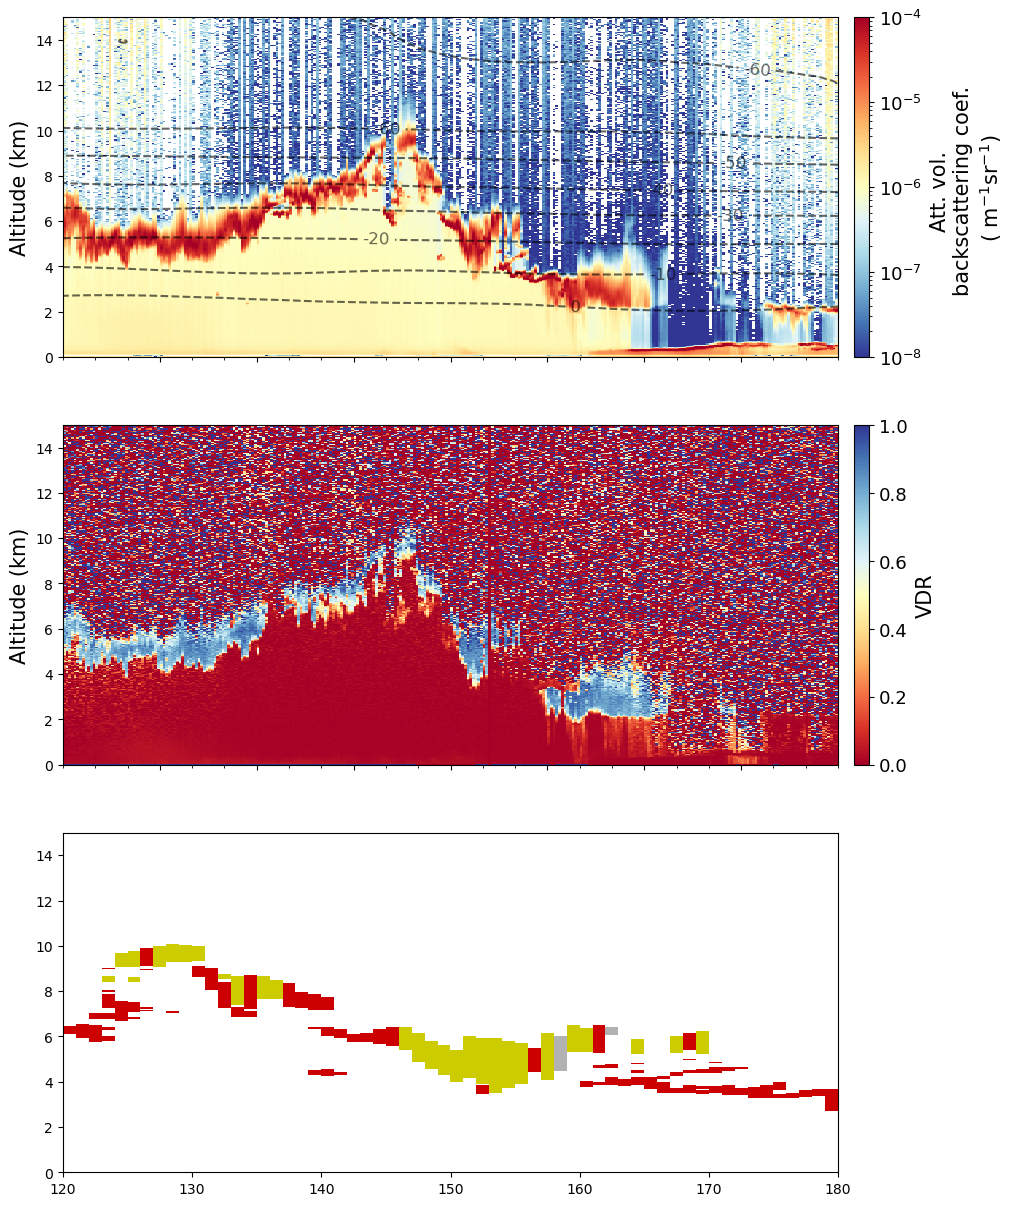

In [121]:
fig, axes = plt.subplots(3,figsize=(10,15))
(ax1, ax2, ax3) = axes

## Fig 1 - ALCF backscatter

Im1=ax1.imshow(ds['backscatter'].values[:].T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    interpolation='None',
    cmap='RdYlBu_r',
    norm=colors.LogNorm(vmin=1e-8,vmax=1e-4),
    
)

cax1 = ax1.inset_axes([1.02,0,0.02,1],transform=ax1.transAxes)

fig.colorbar(Im1,
        extend='neither',
        cax=cax1,
    ).set_label(label='Att. vol. \nbackscattering coef. \n( m$^{-1}$sr$^{-1}$)', size=15, labelpad=6)

ax1.set_ylabel('Altitude (km)', fontsize=15)
ax1.set_xticklabels([])
ax1.set_xticks(np.arange(36,288,36))
ax1.xaxis.set_minor_locator(MultipleLocator(12))
cax1.tick_params(labelsize=13)

CS=ax1.contour(ds['temp'].values[:].T,
            levels=[-60,-50,-40,-30,-20,-10,0],
            colors='k',
            alpha=0.6,
            linestyles='dashed',
            extent=(0, 288, 0, 15),
            )

ax1.clabel(CS,inline=True,fontsize=12,fmt='%.0f')

## Fig 2 - VDR raw data
    
# Im2=ax2.imshow(vdr[:].T,
Im2=ax2.imshow(ds['vdr'].values[:].T,             
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap='RdYlBu'
)

ax2.set_xticklabels([])
ax2.set_xticks(np.arange(36,288,36))
ax2.xaxis.set_minor_locator(MultipleLocator(12))
ax2.set_ylabel('Altitude (km)', fontsize=15)

cax2 = ax2.inset_axes([1.02,0,0.02,1],transform=ax2.transAxes)

fig.colorbar(Im2,
        extend='neither',
        cax=cax2,
    ).set_label(label='VDR', size=15, labelpad=6)

cax2.tick_params(labelsize=13)




## Fig 3 - Reference (VDR) mask

Im3=ax3.imshow(ds['cloud_mask'].values[120:180].T,
    extent=(120, 180, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap5
)

Im3=ax3.imshow(ds['ic'].values[120:180].T,
    extent=(120, 180, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap4
)

Im3=ax3.imshow(ds['slcc'].values[120:180].T,
    extent=(120,180, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap2
)

Im3=ax3.imshow(ds['wlwc'].values[120:180].T,
    extent=(120,180, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap3
)



# ax3.set_xticklabels([])
# ax3.set_xticks(np.arange(36,288,36))
# ax3.xaxis.set_minor_locator(MultipleLocator(12))
# ax3.set_ylabel('Altitude (km)', fontsize=15)

# ax3.contour(temp[:].T,
#             levels=[-40,0],
#             colors='k',
#             linestyles=['dashed','solid'],
#             extent=(0, 288, 0, 15),
#             )


# colour_labels = ['SLCC', 'WLCC', 'ICC']
# patch_colors = [ c2, c3, c4]
# patches_colours = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(3) ]

# patch_linestyles = ['dashed', 'solid']
# linestyle_labels = ['-40 \N{DEGREE SIGN}C', '0 \N{DEGREE SIGN}C']
# patches_lines = [mlines.Line2D([],[],color='k',linestyle=patch_linestyles[i], label=linestyle_labels[i]) for i in range(2)] 
# patches = patches_colours + patches_lines
# ax3.legend(handles=patches, bbox_to_anchor=(1.025, 0.3), loc=6, fontsize=13)#,borderaxespad=0. )
plt.show()


In [133]:
ds['vdr'].values[157]

array([ 1.74988939e+00,  2.40098156e-02,  1.96504593e-02,  1.65737292e-02,
        1.64035600e-02,  1.54789757e-02,  1.45333583e-02,  1.16075209e-02,
        1.28238478e-02,  9.82732329e-03,  1.40695622e-02,  1.02754092e-02,
        9.24605371e-03,  9.80403193e-03,  9.80354965e-03,  8.49446209e-03,
        9.07462897e-03,  1.28594042e-02,  7.78600153e-03,  8.70028408e-03,
        1.00436346e-02,  7.62415212e-03,  8.05627792e-03,  9.91114904e-03,
        1.00048706e-02,  1.13337328e-02,  9.58721479e-03,  1.16070569e-02,
        1.00270057e-02,  5.97542804e-03,  8.28533753e-03,  1.18027311e-02,
        8.05340189e-03,  1.14801580e-02,  1.12309217e-02,  8.53495209e-03,
        6.91705190e-03,  1.04939742e-02,  1.64324008e-02,  9.92668931e-03,
        2.43246425e-03,  1.02343991e-02,  1.14631655e-02,  9.92922120e-03,
        1.47861808e-02,  4.59166833e-03,  1.02092168e-02,  5.14636225e-03,
        1.13370539e-02,  1.22904293e-02,  1.28428914e-02,  8.29738296e-03,
        8.15712546e-03,  